# Evaluación Regular N°2 - Modelos predictivos

Integrantes: [Completar nombres].
Asignatura: Modelos Predictivos en Negocios.
Fecha de entrega: [Completar fecha].


***comentario pollo: este tipo de presentaciones no son malas pero dejarlas asi de simplonas se fácil de identificar como generado por IA, te recomiendo complementar el documento:***


Este trabajo utiliza el Student Performance Prediction Dataset de Kaggle para estudiar el rendimiento académico y la colocación laboral de estudiantes mediante regresión lineal múltiple y regresión logística.


## 1. Contexto, objetivo e hipótesis

Una institución educativa puede utilizar información de sus estudiantes para estimar su rendimiento académico y orientar programas de apoyo y preparación laboral.

El objetivo general es construir y evaluar una regresión lineal múltiple para estimar el puntaje del examen y una regresión logística para estimar la probabilidad de colocación laboral. Se exploran los datos, se seleccionan variables, se evalúan los modelos y se interpretan sus resultados para discutir posibles aplicaciones en la gestión educativa.

La hipótesis principal plantea que más horas de estudio, mayor asistencia y mejores puntajes previos se relacionan con mejores resultados académicos y mayor probabilidad de colocación laboral.

Como hipótesis exploratoria adicional, se plantea que la relación entre estudiar más y obtener mejores puntajes podría ser distinta entre quienes duermen menos de seis horas y quienes duermen seis horas o más. Esta comparación describe diferencias entre grupos; no demuestra causalidad ni modifica los modelos exigidos.


***comentario pollo: aportar una hipotesis alternativa a un fenomeno particular suele ser bien valorado por profesores, aunque si crees que es mucho borra todo lo referente***


## 2. Librerías y carga del dataset


***comentario pollo: el texto a continuación de puede explicar a ti para que se usa cada libreria (por eso lo dejé), pero sinceramente es sospechoso de IA un documento con este tipo de comentarios pues suele ser una respuesta común cuando le pides que te explique su trabajo.***

Se utiliza pandas para organizar los datos, numpy para cálculos, matplotlib y seaborn para gráficos, scikit-learn para entrenar y evaluar los modelos, y kagglehub para descargar el archivo. El trabajo mantiene un enfoque introductorio y no utiliza statsmodels.

El dataset se seleccionó porque contiene, para los mismos estudiantes, un resultado numérico y un resultado binario, además de variables relacionadas con hábitos y desempeño académico. Esto permite desarrollar las dos tareas solicitadas con un mismo conjunto de datos. Su origen en Kaggle y su orientación educativa no garantizan que represente a otra institución.


In [2]:
%pip install -q kagglehub pandas numpy matplotlib seaborn scikit-learn


In [3]:
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import precision_score
from sklearn.metrics import r2_score
from sklearn.metrics import recall_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", "{:.3f}".format)

semilla_aleatoria = 42
proporcion_prueba = 0.20


***comentario pollo: lo mismo para este texto.***

Los nombres originales utilizan minúsculas y guiones bajos. Se normaliza su formato y se renombran `Attendance` como `Attendance Percentage` y `Previous Score` como `Previous Scores` para coincidir con la pauta. Estos cambios afectan únicamente a los nombres, no a los valores.


In [4]:
carpeta_dataset = kagglehub.dataset_download(
    "shambhurajejagadale/student-performance-prediction-dataset"
)
ruta_dataset = Path(carpeta_dataset) / "student_dataset_10000_rows.csv"

datos = pd.read_csv(ruta_dataset)
datos.columns = (
    datos.columns.str.strip()
    .str.replace(r"[_\s]+", " ", regex=True)
    .str.title()
)

# La pauta usa dos nombres diferentes a los del CSV, los vamos a cambiar para que sean coherentes con la pauta.
datos = datos.rename(columns={
    "Attendance": "Attendance Percentage",
    "Previous Score": "Previous Scores",
})

variables_predictoras = [
    "Study Hours",
    "Attendance Percentage",
    "Sleep Hours",
    "Internet Usage",
    "Assignments Completed",
    "Previous Scores",
]

variable_objetivo_lineal = "Exam Score"
variable_objetivo_logistica = "Placement Status"

columnas_requeridas = variables_predictoras + [
    variable_objetivo_lineal,
    variable_objetivo_logistica,
]


print("Filas:", datos.shape[0])
print("Columnas:", datos.shape[1])

# Una muestra visual de como son los dátos
display(datos.head())


Using Colab cache for faster access to the 'student-performance-prediction-dataset' dataset.
Filas: 10000
Columnas: 8


,Study Hours,Attendance Percentage,Sleep Hours,Internet Usage,Assignments Completed,Previous Scores,Exam Score,Placement Status
0,7,56,8,7,10,62,100.000,Placed
1,4,69,5,3,8,56,100.000,Placed
2,11,60,7,6,10,45,100.000,Placed
3,8,99,9,8,4,55,90.170,Placed
4,5,52,8,6,8,40,78.820,Placed


## 3. Exploración básica antes de limpiar

Se revisan dimensiones, tipos de datos, faltantes, duplicados y estadísticas descriptivas. Los histogramas de horas de estudio, horas de sueño y puntaje del examen permiten reconocer sus distribuciones y orientar la limpieza.


,Tipo de dato,Valores faltantes,Porcentaje faltante
Study Hours,int64,0,0.000
Attendance Percentage,int64,0,0.000
Sleep Hours,int64,0,0.000
Internet Usage,int64,0,0.000
Assignments Completed,int64,0,0.000
Previous Scores,int64,0,0.000
Exam Score,float64,0,0.000
Placement Status,object,0,0.000


,Study Hours,Attendance Percentage,Sleep Hours,Internet Usage,Assignments Completed,Previous Scores,Exam Score
count,10000.000,10000.000,10000.000,10000.000,10000.000,10000.000,10000.000
mean,5.990,69.885,6.498,6.063,9.988,64.911,86.704
std,3.164,17.617,1.709,3.138,6.034,17.503,15.058
min,1.000,40.000,4.000,1.000,0.000,35.000,26.670
25%,3.000,55.000,5.000,3.000,5.000,50.000,76.728
50%,6.000,70.000,6.500,6.000,10.000,65.000,92.120
75%,9.000,85.000,8.000,9.000,15.000,80.000,100.000
max,11.000,100.000,9.000,11.000,20.000,95.000,100.000


Filas completamente duplicadas: 0


,count
Placement Status,
Placed,8356
Not Placed,1644


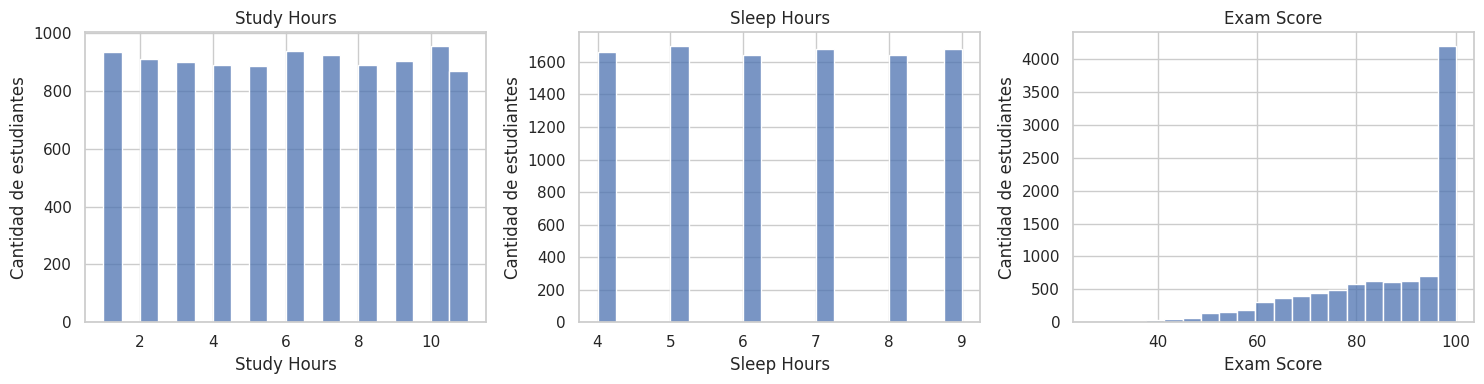

In [5]:
resumen_inicial = pd.DataFrame({
    "Tipo de dato": datos.dtypes.astype(str),
    "Valores faltantes": datos.isna().sum(),
    "Porcentaje faltante": datos.isna().mean() * 100,
})

display(resumen_inicial)
display(datos.describe())
print("Filas completamente duplicadas:", datos.duplicated().sum())
display(datos[variable_objetivo_logistica].value_counts(dropna=False))

variables_graficos = ["Study Hours", "Sleep Hours", "Exam Score"]
figura, ejes = plt.subplots(1, 3, figsize=(15, 4))

for posicion, nombre_variable in enumerate(variables_graficos):
    valores_numericos = pd.to_numeric(
        datos[nombre_variable],
        errors="coerce",
    )
    sns.histplot(
        valores_numericos.dropna(),
        bins=20,
        ax=ejes[posicion],
    )
    ejes[posicion].set_title(nombre_variable)
    ejes[posicion].set_ylabel("Cantidad de estudiantes")

plt.tight_layout()
plt.show()


El dataset contiene 10.000 estudiantes y ocho variables. No se encontraron valores faltantes ni filas completamente duplicadas. Las horas de estudio presentan un promedio de 5,99 horas diarias y las horas de sueño un promedio de 6,50 horas. La asistencia promedio es de 69,89 %.

Los histogramas muestran frecuencias relativamente parejas entre los valores registrados de estudio y sueño. El puntaje del examen se concentra en valores altos, especialmente en 100 puntos. Su promedio es de 86,70 puntos y su mediana de 92,12 puntos. Esta acumulación será relevante al interpretar el modelo lineal.

En colocación laboral, 8.356 estudiantes aparecen como colocados y 1.644 como no colocados: 83,56 % y 16,44 %, respectivamente. Las clases están desbalanceadas, por lo que una accuracy elevada debe compararse con la estrategia de predecir siempre la clase mayoritaria.


## 4. Limpieza y selección de variables

Se comprueban duplicados exactos, resultados faltantes y valores físicamente imposibles. Los duplicados solo se consideran repetidos si no hay evidencia de que correspondan a personas diferentes. Las filas sin alguno de los resultados se excluirían para mantener una muestra común para ambos modelos.

Se seleccionan como predictores las horas de estudio, asistencia, sueño, uso de internet, tareas completadas y puntajes previos. El puntaje del examen es el objetivo de la regresión lineal y la colocación laboral es el objetivo de la logística, codificada como 1 para colocado y 0 para no colocado.


In [8]:
datos_limpios = datos[columnas_requeridas].copy()

columnas_numericas = variables_predictoras + [
    variable_objetivo_lineal
]

codificacion_estado_laboral = {
    "Not Placed": 0,
    "Placed": 1,
}

datos_limpios[variable_objetivo_logistica] = (
    datos_limpios[variable_objetivo_logistica]
    .map(codificacion_estado_laboral)
)

print("Registros conservados:", len(datos_limpios))
display(datos_limpios[variable_objetivo_logistica].value_counts())

Registros conservados: 10000


,count
Placement Status,
1,8356
0,1644


El análisis exploratorio no identificó valores faltantes, duplicados ni valores fuera de los rangos revisados, por lo que se conservaron los 10.000 registros sin aplicar tratamientos adicionales.
Se seleccionaron las seis variables predictoras definidas anteriormente y los dos resultados que se quieren predecir. La colocación laboral se codificó como 1 para estudiantes colocados y 0 para no colocados, para utilizarla en la regresión logística.

## 5. Valores atípicos

El rango intercuartílico o IQR permite señalar observaciones poco frecuentes. Se calculan límites de 1,5 veces el IQR por debajo del primer cuartil y por encima del tercer cuartil. Un valor fuera de estos límites no constituye necesariamente un error.


,Variable,Límite inferior IQR,Límite superior IQR,Cantidad señalada
0,Study Hours,-6.000,18.000,0
1,Attendance Percentage,10.000,130.000,0
2,Sleep Hours,0.500,12.500,0
3,Internet Usage,-6.000,18.000,0
4,Assignments Completed,-10.000,30.000,0
5,Previous Scores,5.000,125.000,0
6,Exam Score,41.819,134.909,62


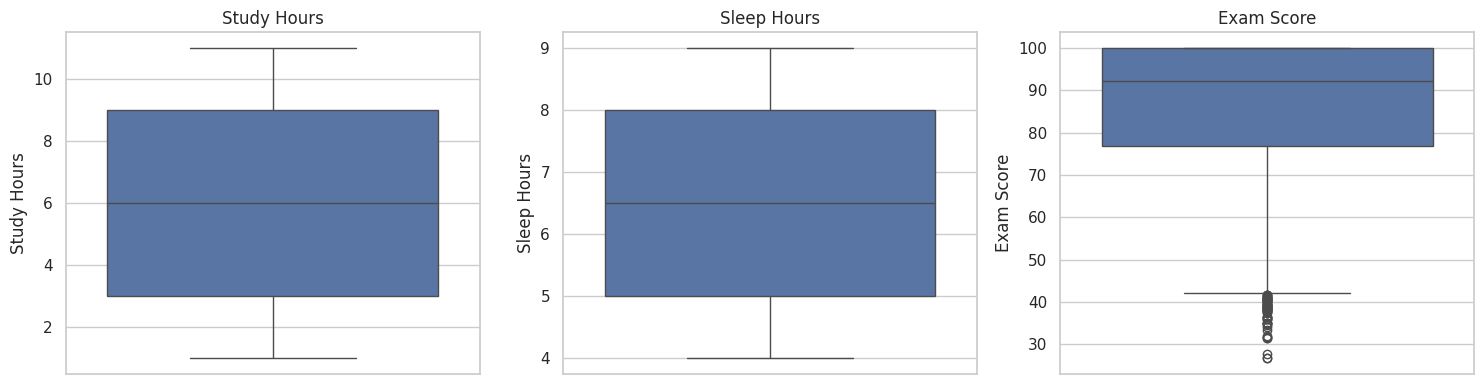

In [ ]:
resumen_atipicos = []

for nombre_variable in columnas_numericas:
    valores = datos_limpios[nombre_variable].dropna()
    primer_cuartil = valores.quantile(0.25)
    tercer_cuartil = valores.quantile(0.75)
    rango_intercuartilico = tercer_cuartil - primer_cuartil

    limite_inferior = primer_cuartil - 1.5 * rango_intercuartilico
    limite_superior = tercer_cuartil + 1.5 * rango_intercuartilico

    cantidad_atipicos = (
        (valores < limite_inferior)
        | (valores > limite_superior)
    ).sum()

    resumen_atipicos.append({
        "Variable": nombre_variable,
        "Límite inferior IQR": limite_inferior,
        "Límite superior IQR": limite_superior,
        "Cantidad señalada": int(cantidad_atipicos),
    })

display(pd.DataFrame(resumen_atipicos))

figura, ejes = plt.subplots(1, 3, figsize=(15, 4))

for posicion, nombre_variable in enumerate(variables_graficos):
    sns.boxplot(
        y=datos_limpios[nombre_variable],
        ax=ejes[posicion],
    )
    ejes[posicion].set_title(nombre_variable)

plt.tight_layout()
plt.show()


El método no señaló valores atípicos en las seis variables predictoras. En el puntaje del examen identificó 62 observaciones por debajo de aproximadamente 41,82 puntos, equivalentes al 0,62 % del dataset.

Estas observaciones se conservaron porque un puntaje bajo es posible y no representa por sí mismo un error. Eliminarlas reduciría la representación de estudiantes con bajo rendimiento, precisamente relevantes para orientar apoyos académicos.

El diagrama de caja del examen también muestra una concentración de puntajes altos y una cola hacia resultados bajos. Esto ayuda a explicar por qué el criterio IQR señala algunos puntajes bajos.


## 6. División de entrenamiento y prueba

Se utiliza el 80 % de los estudiantes para entrenamiento y el 20 % para prueba, con `random_state=42`. La división estratificada conserva aproximadamente la proporción de colocados y no colocados en ambos grupos. Ambos modelos utilizan los mismos estudiantes de entrenamiento y prueba.

Las medianas, la revisión de variables constantes y la estandarización se ajustan únicamente con entrenamiento, evitando utilizar información de prueba en la preparación de los modelos.


In [11]:
# Dividir los datos en entrenamiento y prueba.
datos_entrenamiento, datos_prueba = train_test_split(
    datos_limpios,
    test_size=proporcion_prueba,
    random_state=semilla_aleatoria,
    stratify=datos_limpios[variable_objetivo_logistica],
)

variables_utilizadas = variables_predictoras.copy()

# Seleccionar las variables predictoras.
predictores_entrenamiento_completos = (
    datos_entrenamiento[variables_utilizadas]
)

predictores_prueba_completos = (
    datos_prueba[variables_utilizadas]
)

# Separar los resultados que queremos predecir.
puntaje_entrenamiento = (
    datos_entrenamiento[variable_objetivo_lineal]
)

puntaje_prueba = (
    datos_prueba[variable_objetivo_lineal]
)

colocacion_entrenamiento = (
    datos_entrenamiento[variable_objetivo_logistica]
)

colocacion_prueba = (
    datos_prueba[variable_objetivo_logistica]
)

# Estandarizar los predictores para la regresión logística.
estandarizador = StandardScaler()

predictores_entrenamiento_estandarizados = (
    estandarizador.fit_transform(
        predictores_entrenamiento_completos
    )
)

predictores_prueba_estandarizados = (
    estandarizador.transform(
        predictores_prueba_completos
    )
)

print("Estudiantes en entrenamiento:", len(datos_entrenamiento))
print("Estudiantes en prueba:", len(datos_prueba))

Estudiantes en entrenamiento: 8000
Estudiantes en prueba: 2000


Se dividieron los datos en 8.000 estudiantes para entrenamiento y 2.000 para prueba, correspondientes al 80 % y 20 % de la muestra. Se utilizó una semilla de 42 para reproducir la división y se mantuvo aproximadamente la proporción de colocados y no colocados en ambos conjuntos.
La regresión lineal utiliza los predictores en sus unidades originales. Para la regresión logística se estandarizaron utilizando el promedio y la desviación estándar de entrenamiento. Esa misma transformación se aplicó a prueba, sin calcular nuevamente los parámetros.
No fue necesario completar datos faltantes, porque el análisis exploratorio confirmó que todas las variables estaban completas.

## 7. Hipótesis adicional y relaciones básicas

Se utiliza únicamente entrenamiento para comparar grupos y explorar relaciones. Se considera estudio alto estudiar seis horas o más, según la mediana de entrenamiento, y sueño corto dormir menos de seis horas diarias. El límite de estudio es relativo a esta muestra y no una recomendación académica.

Se muestran cantidades, promedios y desviaciones estándar para interpretar las diferencias considerando el tamaño y la dispersión de cada grupo.


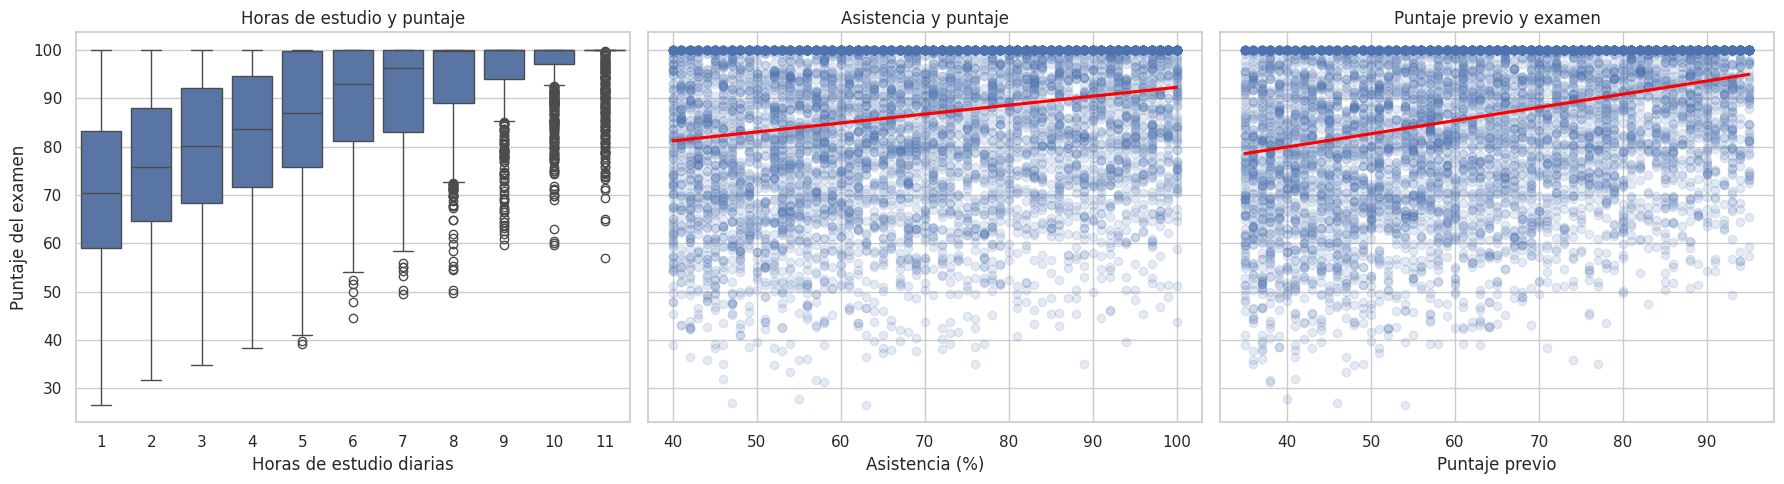

In [14]:
# Organizar los tres gráficos en una sola fila.
figura, ejes = plt.subplots(
    1,
    3,
    figsize=(18, 5),
    sharey=True,
)

# Primer gráfico: puntajes agrupados por horas de estudio.
sns.boxplot(
    data=datos_entrenamiento,
    x="Study Hours",
    y="Exam Score",
    ax=ejes[0],
)

ejes[0].set_title("Horas de estudio y puntaje")
ejes[0].set_xlabel("Horas de estudio diarias")
ejes[0].set_ylabel("Puntaje del examen")

# Segundo gráfico: asistencia y puntaje.
sns.regplot(
    data=datos_entrenamiento,
    x="Attendance Percentage",
    y="Exam Score",
    ci=None,
    scatter_kws={"alpha": 0.15},
    line_kws={"color": "red"},
    ax=ejes[1],
)

ejes[1].set_title("Asistencia y puntaje")
ejes[1].set_xlabel("Asistencia (%)")
ejes[1].set_ylabel("")

# Tercer gráfico: puntaje previo y puntaje del examen.
sns.regplot(
    data=datos_entrenamiento,
    x="Previous Scores",
    y="Exam Score",
    ci=None,
    scatter_kws={"alpha": 0.15},
    line_kws={"color": "red"},
    ax=ejes[2],
)

ejes[2].set_title("Puntaje previo y examen")
ejes[2].set_xlabel("Puntaje previo")
ejes[2].set_ylabel("")

plt.tight_layout()
plt.show()

In [8]:
# Agrupar estudiantes según sus horas de estudio y sueño.
datos_hipotesis = datos_entrenamiento.copy()

mediana_horas_estudio = datos_hipotesis["Study Hours"].median()

datos_hipotesis["Grupo de estudio"] = np.where(
    datos_hipotesis["Study Hours"] >= mediana_horas_estudio,
    "Igual o superior a la mediana",
    "Inferior a la mediana",
)

datos_hipotesis["Grupo de sueño"] = np.where(
    datos_hipotesis["Sleep Hours"] < 6,
    "Menos de 6 horas",
    "6 horas o más",
)

# Comparar cantidad de estudiantes, promedio y dispersión.
comparacion_hipotesis = datos_hipotesis.groupby(
    ["Grupo de sueño", "Grupo de estudio"]
)["Exam Score"].agg(["count", "mean", "std"])

comparacion_hipotesis = comparacion_hipotesis.rename(columns={
    "count": "Cantidad de estudiantes",
    "mean": "Puntaje promedio",
    "std": "Desviación estándar",
})

print("Mediana de horas de estudio:", mediana_horas_estudio)
display(comparacion_hipotesis)

# Revisar las correlaciones entre las variables numéricas.
correlaciones_entrenamiento = (
    datos_entrenamiento[columnas_numericas].corr()
)

display(correlaciones_entrenamiento)

medianas_por_hora = datos_entrenamiento.groupby(
    "Study Hours"
)["Exam Score"].median()

display(medianas_por_hora)

# Organizar los promedios como una tabla dinámica.
promedios_por_grupo = datos_hipotesis.pivot_table(
    index="Grupo de sueño",
    columns="Grupo de estudio",
    values="Exam Score",
    aggfunc="mean",
)

# Calcular la diferencia entre estudio alto y bajo.
promedios_por_grupo["Diferencia de puntaje"] = (
    promedios_por_grupo["Igual o superior a la mediana"]
    - promedios_por_grupo["Inferior a la mediana"]
)

display(promedios_por_grupo.round(2))

Mediana de horas de estudio: 6.0


Cantidad de estudiantes  \
Grupo de sueño   Grupo de estudio                                         
6 horas o más    Igual o superior a la mediana                     2905   
                 Inferior a la mediana                             2427   
Menos de 6 horas Igual o superior a la mediana                     1466   
                 Inferior a la mediana                             1202   

                                                Puntaje promedio  \
Grupo de sueño   Grupo de estudio                                  
6 horas o más    Igual o superior a la mediana            94.576   
                 Inferior a la mediana                    80.180   
Menos de 6 horas Igual o superior a la mediana            91.811   
                 Inferior a la mediana                    74.884   

                                                Desviación estándar  
Grupo de sueño   Grupo de estudio                                    
6 horas o más    Igual o superior a la mediana                9.191  
                 Inferior a la mediana                       15.467  
Menos de 6 horas Igual o superior a la mediana               11.299  
                 Inferior a la mediana                       16.304

,Study Hours,Attendance Percentage,Sleep Hours,Internet Usage,Assignments Completed,Previous Scores,Exam Score
Study Hours,1.000,0.002,-0.002,-0.003,-0.006,0.003,0.560
Attendance Percentage,0.002,1.000,-0.002,-0.011,-0.017,-0.004,0.216
Sleep Hours,-0.002,-0.002,1.000,0.006,-0.001,0.026,0.146
Internet Usage,-0.003,-0.011,0.006,1.000,0.016,-0.001,-0.156
Assignments Completed,-0.006,-0.017,-0.001,0.016,1.000,0.015,0.398
Previous Scores,0.003,-0.004,0.026,-0.001,0.015,1.000,0.317
Exam Score,0.560,0.216,0.146,-0.156,0.398,0.317,1.000


Study Hours
1     70.430
2     75.910
3     80.240
4     83.700
5     86.980
6     92.990
7     96.235
8     99.740
9    100.000
10   100.000
11   100.000
Name: Exam Score, dtype: float64

Grupo de estudio,Igual o superior a la mediana,Inferior a la mediana,Diferencia de puntaje
Grupo de sueño,,,
6 horas o más,94.580,80.180,14.400
Menos de 6 horas,91.810,74.880,16.930


Entre quienes dormían seis horas o más, los 2.905 estudiantes con estudio alto obtuvieron un promedio de 94,58 puntos, frente a 80,18 puntos de los 2.427 con estudio bajo: una diferencia de 14,40 puntos.

Entre quienes dormían menos de seis horas, los 1.466 estudiantes con estudio alto obtuvieron 91,81 puntos en promedio, frente a 74,88 de los 1.202 con estudio bajo: una diferencia de 16,93 puntos.

Estudiar más se asoció con mejores promedios en ambos grupos de sueño. No se observó que esa ventaja desapareciera al dormir poco; descriptivamente, la diferencia fue incluso mayor en ese grupo. Dentro de cada nivel de estudio, quienes dormían seis horas o más presentaron mejores promedios.

Esta comparación no controla otras diferencias entre estudiantes ni incluye una prueba formal de interacción. Por eso no demuestra que estudiar o dormir más cause un mejor resultado. Las desviaciones estándar también muestran variación relevante dentro de los grupos.

Las horas de estudio presentan la correlación positiva más marcada con el examen, con 0,560, seguidas por tareas completadas, con 0,398, y puntajes previos, con 0,317. El uso de internet presenta una correlación negativa de −0,156. Las correlaciones entre predictores son cercanas a cero, sin relaciones lineales fuertes entre ellos en esta muestra.


***comentario pollo: de aqui en adelante puede ser complejo, pero tienes que estudiarlo y entenderlo si quieres persentarlo: puedes preguntarme cualquier cosa que no entiendas. Recuerda borrar este comentario.***

## 8. Regresión lineal múltiple

La regresión lineal estima el puntaje del examen utilizando los seis predictores. Sus coeficientes indican el cambio estimado de puntaje al aumentar una unidad de cada variable, manteniendo constantes las demás. Una unidad de asistencia corresponde a un punto porcentual.

Se evalúan MAE, RMSE y R² en prueba y se comparan con una referencia que siempre predice el promedio de entrenamiento.


In [ ]:
modelo_lineal = LinearRegression()
modelo_lineal.fit(
    predictores_entrenamiento_completos,
    puntaje_entrenamiento,
)

puntajes_predichos = modelo_lineal.predict(predictores_prueba_completos)

coeficientes_lineales = pd.DataFrame({
    "Variable": variables_utilizadas,
    "Cambio de puntaje por una unidad": modelo_lineal.coef_,
})

print("Intercepto del modelo lineal:", modelo_lineal.intercept_)
display(coeficientes_lineales)

error_absoluto_medio = mean_absolute_error(
    puntaje_prueba,
    puntajes_predichos,
)
raiz_error_cuadratico_medio = np.sqrt(
    mean_squared_error(puntaje_prueba, puntajes_predichos)
)
coeficiente_determinacion = r2_score(
    puntaje_prueba,
    puntajes_predichos,
)

modelo_referencia_lineal = DummyRegressor(strategy="mean")
modelo_referencia_lineal.fit(
    predictores_entrenamiento_completos,
    puntaje_entrenamiento,
)
puntajes_referencia = modelo_referencia_lineal.predict(
    predictores_prueba_completos
)

metricas_lineales = pd.DataFrame({
    "Modelo": ["Regresión lineal", "Promedio de entrenamiento"],
    "MAE": [
        error_absoluto_medio,
        mean_absolute_error(puntaje_prueba, puntajes_referencia),
    ],
    "RMSE": [
        raiz_error_cuadratico_medio,
        np.sqrt(mean_squared_error(puntaje_prueba, puntajes_referencia)),
    ],
    "R cuadrado": [
        coeficiente_determinacion,
        r2_score(puntaje_prueba, puntajes_referencia),
    ],
})

display(metricas_lineales)


Intercepto del modelo lineal: 26.920012980668723


,Variable,Cambio de puntaje por una unidad
0,Study Hours,2.671
1,Attendance Percentage,0.189
2,Sleep Hours,1.244
3,Internet Usage,-0.765
4,Assignments Completed,1.004
5,Previous Scores,0.264


,Modelo,MAE,RMSE,R cuadrado
0,Regresión lineal,6.917,8.791,0.653
1,Promedio de entrenamiento,12.546,14.932,-0.000


El modelo relaciona más horas de estudio, mayor asistencia, más horas de sueño, más tareas completadas y mejores puntajes previos con un mayor puntaje en el examen. El uso de internet presenta una relación negativa. Por ejemplo, al comparar estudiantes con los mismos valores en las demás variables, una hora adicional de estudio corresponde a una estimación de 2,67 puntos más, una tarea adicional a 1,00 punto más y una hora adicional de internet a 0,77 puntos menos. Esto describe lo que estima el modelo, pero no asegura que cambiar esos hábitos produzca exactamente esos resultados.

El **MAE fue de 6,917 puntos**. Esto significa que las predicciones se alejaron de los puntajes reales en aproximadamente 6,92 puntos, en promedio, sin considerar si el modelo estimó de más o de menos. La referencia, que siempre predice el promedio de entrenamiento, obtuvo un MAE de 12,546 puntos. Por lo tanto, el modelo redujo el error promedio aproximadamente un 45 %.

El **RMSE fue de 8,791 puntos**, frente a 14,932 de la referencia. Esta medida da más peso a las equivocaciones grandes. Su resultado muestra que también debemos considerar esos errores, porque el modelo puede acercarse bastante al puntaje de algunos estudiantes y equivocarse más con otros.

El **R² fue de 0,653**. Esto indica que el modelo explica aproximadamente el 65,3 % de las diferencias observadas entre los puntajes de los estudiantes del conjunto de prueba. No significa que haya acertado el puntaje exacto del 65,3 % de ellos. La referencia obtuvo un R² cercano a cero.

En general, el modelo entrega mejores estimaciones que utilizar solamente el promedio. Podría servir como apoyo para identificar estudiantes que necesitan tutorías, pero sus errores muestran que también habría que revisar otra información antes de decidir.

Finalmente, el intercepto fue de 26,92. Es el puntaje que la fórmula estima cuando todos los predictores valen cero. Como esa situación queda fuera de los valores observados en varias variables, no lo interpretamos como el resultado de un estudiante típico.

## 9. Regresión logística

La regresión logística estima la probabilidad de colocación laboral. Se clasifica como colocado cuando la probabilidad es igual o superior a 0,50. Se utiliza la configuración habitual de scikit-learn, con regularización L2 y sin ajustar hiperparámetros mediante el conjunto de prueba.

Se analizan accuracy, precision y recall, tomando colocado como clase positiva. La matriz de confusión permite interpretar los errores según su consecuencia práctica. Los coeficientes se convierten a unidades originales para calcular odds ratios por hora, tarea, punto o punto porcentual.


,Variable,Coeficiente en unidades originales,Odds ratio por una unidad
0,Study Hours,0.728,2.072
1,Attendance Percentage,0.058,1.060
2,Sleep Hours,0.365,1.440
3,Internet Usage,-0.215,0.807
4,Assignments Completed,0.272,1.313
5,Previous Scores,0.070,1.073


,Modelo,Accuracy (%),Precision de colocados (%),Sensibilidad: colocados (%),Especificidad: no colocados (%)
0,Regresión logística,90.650,93.090,95.930,63.830
1,Clase más frecuente,83.550,83.550,100.000,0.000


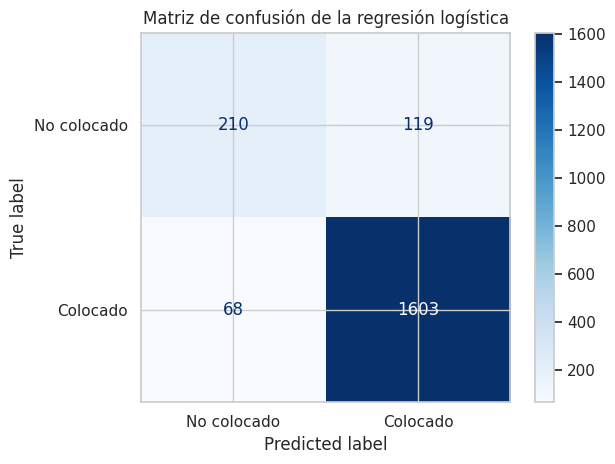

In [18]:
# Entrenar el modelo de regresión logística.
modelo_logistico = LogisticRegression(
    max_iter=2000,
    random_state=semilla_aleatoria,
)

modelo_logistico.fit(
    predictores_entrenamiento_estandarizados,
    colocacion_entrenamiento,
)

# Estimar la probabilidad de colocación laboral.
probabilidades_colocacion = modelo_logistico.predict_proba(
    predictores_prueba_estandarizados
)[:, 1]

umbral_clasificacion = 0.50

colocaciones_predichas = (
    probabilidades_colocacion >= umbral_clasificacion
).astype(int)

# Expresar los coeficientes en las unidades originales.
coeficientes_logisticos_originales = (
    modelo_logistico.coef_[0] / estandarizador.scale_
)

coeficientes_logisticos = pd.DataFrame({
    "Variable": variables_utilizadas,
    "Coeficiente en unidades originales": coeficientes_logisticos_originales,
    "Odds ratio por una unidad": np.exp(
        coeficientes_logisticos_originales
    ),
})

display(coeficientes_logisticos)

# Evaluar las predicciones del modelo.
exactitud = accuracy_score(
    colocacion_prueba,
    colocaciones_predichas,
)

precision = precision_score(
    colocacion_prueba,
    colocaciones_predichas,
    pos_label=1,
)

sensibilidad = recall_score(
    colocacion_prueba,
    colocaciones_predichas,
    pos_label=1,
)

especificidad = recall_score(
    colocacion_prueba,
    colocaciones_predichas,
    pos_label=0,
)

# Crear una referencia que predice siempre la clase más frecuente.
modelo_referencia_logistico = DummyClassifier(
    strategy="most_frequent"
)

modelo_referencia_logistico.fit(
    predictores_entrenamiento_estandarizados,
    colocacion_entrenamiento,
)

colocaciones_referencia = modelo_referencia_logistico.predict(
    predictores_prueba_estandarizados
)

# Evaluar las predicciones de la referencia.
exactitud_referencia = accuracy_score(
    colocacion_prueba,
    colocaciones_referencia,
)

precision_referencia = precision_score(
    colocacion_prueba,
    colocaciones_referencia,
    pos_label=1,
)

sensibilidad_referencia = recall_score(
    colocacion_prueba,
    colocaciones_referencia,
    pos_label=1,
)

especificidad_referencia = recall_score(
    colocacion_prueba,
    colocaciones_referencia,
    pos_label=0,
)

# Comparar los resultados como porcentajes.
metricas_logisticas = pd.DataFrame({
    "Modelo": [
        "Regresión logística",
        "Clase más frecuente",
    ],
    "Accuracy (%)": [
        exactitud * 100,
        exactitud_referencia * 100,
    ],
    "Precision de colocados (%)": [
        precision * 100,
        precision_referencia * 100,
    ],
    "Sensibilidad: colocados (%)": [
        sensibilidad * 100,
        sensibilidad_referencia * 100,
    ],
    "Especificidad: no colocados (%)": [
        especificidad * 100,
        especificidad_referencia * 100,
    ],
})

display(metricas_logisticas.round(2))

# Mostrar los aciertos y errores de clasificación.
ConfusionMatrixDisplay.from_predictions(
    colocacion_prueba,
    colocaciones_predichas,
    labels=[0, 1],
    display_labels=["No colocado", "Colocado"],
    cmap="Blues",
    values_format="d",
)

plt.title("Matriz de confusión de la regresión logística")
plt.tight_layout()
plt.show()

Los resultados del modelo relacionan más horas de estudio, mayor asistencia, más horas de sueño, más tareas completadas y mejores puntajes previos con una mayor probabilidad de colocación laboral. El uso de internet presenta una relación negativa. Estas relaciones se estiman manteniendo iguales los valores de las demás variables y no demuestran que cambiar un hábito produzca directamente una mejora.

Para interpretar los coeficientes usamos los **odds ratios**. Las odds comparan la probabilidad de colocarse con la de no colocarse: se calculan dividiendo la primera por la segunda. Un odds ratio mayor que 1 indica una relación positiva con la colocación y uno menor que 1 indica una relación negativa.

Una hora adicional de estudio presenta un odds ratio de 2,072, por lo que las odds estimadas de colocación son aproximadamente el doble. Una tarea adicional presenta un valor de 1,313 y una hora adicional de internet uno de 0,807. Esto no significa que la probabilidad aumente o disminuya en esa misma proporción.

La **accuracy fue de 90,65 %**: el modelo clasificó correctamente a 1.813 de los 2.000 estudiantes. La referencia, que clasifica a todos como colocados, obtuvo un 83,55 %. El modelo mejora ese resultado en 7,10 puntos porcentuales.

La **precisión fue de 93,09 %**. De los 1.722 estudiantes que el modelo clasificó como colocados, 1.603 realmente lo estaban. Los otros 119 no estaban colocados, aunque el modelo entregó una predicción favorable.

La **sensibilidad fue de 95,93 %**. El modelo identificó correctamente a 1.603 de los 1.671 estudiantes realmente colocados. Esto muestra que reconoce a la mayoría de los estudiantes de ese estado.

La **especificidad fue de 63,83 %**. De los 329 estudiantes que no estaban colocados, el modelo identificó correctamente a 210. Los otros 119 fueron clasificados como colocados. Por lo tanto, el modelo reconoce mejor a los colocados que a los no colocados.

Esta diferencia importa si la institución quiere identificar estudiantes que necesitan apoyo para encontrar trabajo. Una accuracy alta puede dar una impresión favorable del modelo, pero también debemos revisar cuántos casos de no colocación logra detectar. Los 119 casos que no detectó podrían quedar sin apoyo si se utilizara solamente su predicción.

La referencia tiene una sensibilidad de 100 %, porque clasifica a todos como colocados, pero una especificidad de 0 %, porque no identifica a ningún no colocado. Esto muestra por qué no basta con revisar una sola métrica.

En general, el modelo mejora frente a la referencia, pero todavía tiene dificultades para identificar parte de los estudiantes no colocados. Sus predicciones podrían apoyar la orientación laboral, siempre que se complementen con otra información antes de decidir a quién ofrecer ayuda.

## 10. Revisión de los modelos y variables relevantes

Revisamos los gráficos para reconocer las dificultades del modelo y comparamos qué variables destacan en sus resultados.

En el siguiente gráfico, cada punto representa un estudiante del conjunto de prueba. La línea roja indica dónde el puntaje estimado coincide con el real. Los puntos cercanos a esa línea muestran predicciones más acertadas.

La tabla ordena las variables dentro de cada modelo. Para hacer esta comparación se consideran sus diferentes escalas, ya que una hora de estudio y un punto de asistencia no representan el mismo cambio.


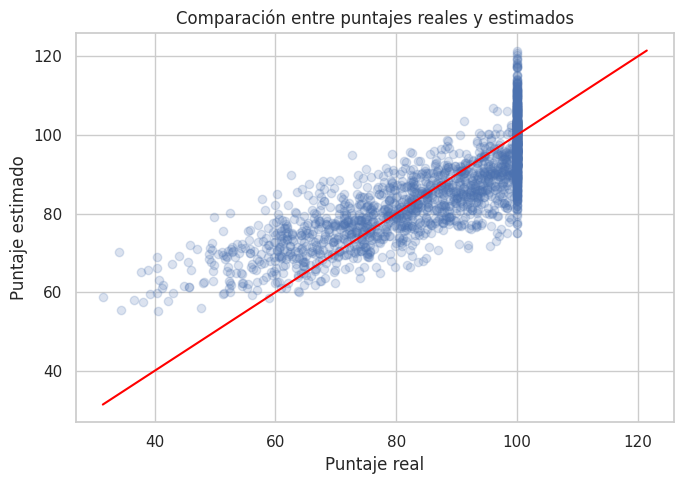

,Orden,Regresión lineal,Regresión logística
0,1,Study Hours,Study Hours
1,2,Assignments Completed,Assignments Completed
2,3,Previous Scores,Previous Scores
3,4,Attendance Percentage,Attendance Percentage
4,5,Internet Usage,Internet Usage
5,6,Sleep Hours,Sleep Hours


In [11]:
# Comparar los puntajes reales con los estimados.
plt.figure(figsize=(7, 5))

plt.scatter(
    puntaje_prueba,
    puntajes_predichos,
    alpha=0.20,
)

puntaje_minimo = min(puntaje_prueba.min(), puntajes_predichos.min())
puntaje_maximo = max(puntaje_prueba.max(), puntajes_predichos.max())

plt.plot(
    [puntaje_minimo, puntaje_maximo],
    [puntaje_minimo, puntaje_maximo],
    color="red",
)

plt.xlabel("Puntaje real")
plt.ylabel("Puntaje estimado")
plt.title("Comparación entre puntajes reales y estimados")
plt.tight_layout()
plt.show()

# Comparar los coeficientes considerando la escala de las variables.
efectos_lineales_comparables = (
    modelo_lineal.coef_ * estandarizador.scale_
)

comparacion_variables = pd.DataFrame({
    "Variable": variables_utilizadas,
    "Magnitud en regresión lineal": np.abs(efectos_lineales_comparables),
    "Magnitud en regresión logística": np.abs(modelo_logistico.coef_[0]),
})

orden_variables_lineales = comparacion_variables.sort_values(
    "Magnitud en regresión lineal",
    ascending=False,
)["Variable"].tolist()

orden_variables_logisticas = comparacion_variables.sort_values(
    "Magnitud en regresión logística",
    ascending=False,
)["Variable"].tolist()

orden_variables = pd.DataFrame({
    "Orden": range(1, len(variables_utilizadas) + 1),
    "Regresión lineal": orden_variables_lineales,
    "Regresión logística": orden_variables_logisticas,
})

display(orden_variables)


Los gráficos anteriores muestran que estudiar más, tener mayor asistencia y contar con mejores puntajes previos se relaciona con mejores resultados en el examen. Las líneas de ajuste resumen estas tendencias, aunque los estudiantes no obtienen todos el mismo resultado. Por eso, una relación lineal sirve como aproximación, pero no representa perfectamente los datos.

También observamos que muchos puntajes llegan a 100. En el gráfico de puntajes reales y estimados aparecen predicciones superiores a ese máximo observado. Esto muestra una dificultad del modelo lineal para representar los resultados más altos.

Al comparar las variables considerando sus diferentes escalas, las horas de estudio destacan en ambos modelos, seguidas por las tareas completadas y los puntajes previos. El uso de internet presenta una relación negativa con los resultados.

Estos resultados coinciden con nuestra hipótesis principal, pero no permiten asegurar que cambiar una característica produzca directamente un mejor resultado. El orden de la tabla corresponde a los coeficientes de los modelos y no demuestra cuál variable causa un mejor desempeño.

Finalmente, no conocemos suficientemente cómo se recopilaron los datos para confirmar que los registros sean independientes entre sí. Por ejemplo, no sabemos si hay estudiantes de un mismo curso que compartan condiciones similares. Esto queda como una limitación del trabajo.


## 11. Predicciones para estudiantes no utilizados en entrenamiento

La siguiente tabla muestra diez estudiantes del conjunto de prueba. Comparamos sus resultados reales con las predicciones para observar algunos aciertos y errores de los modelos.

La columna «Fila original» permite reconocer cada registro del archivo. No se utiliza para hacer las predicciones.


In [ ]:
resultados_prueba = pd.DataFrame({
    "Fila original": datos_prueba.index,
    "Puntaje real": puntaje_prueba.to_numpy(),
    "Puntaje estimado": puntajes_predichos,
    "Colocación real": colocacion_prueba.to_numpy(),
    "Colocación estimada": colocaciones_predichas,
    "Probabilidad de colocación": probabilidades_colocacion,
})

resultados_prueba["Error absoluto del puntaje"] = np.abs(
    resultados_prueba["Puntaje real"] - resultados_prueba["Puntaje estimado"]
)

display(resultados_prueba.head(10))


,Fila original,Puntaje real,Puntaje estimado,Colocación real,Colocación estimada,Probabilidad de colocación,Error absoluto del puntaje
0,4768,100.000,74.997,1,1,0.641,25.003
1,1131,85.510,86.295,1,1,0.975,0.785
2,6125,75.800,89.351,1,1,0.991,13.551
3,2781,52.320,62.870,0,0,0.056,10.550
4,17,91.890,83.823,1,1,0.959,8.067
5,2290,100.000,96.881,1,1,0.999,3.119
6,1879,100.000,89.393,1,1,0.992,10.607
7,935,87.850,82.324,1,1,0.943,5.526
8,13,100.000,92.304,1,1,0.996,7.696
9,9082,94.030,99.963,1,1,0.999,5.933


En el registro 1131, el puntaje real fue de 85,51 y el estimado de 86,30. La diferencia fue de aproximadamente 0,79 puntos, por lo que la predicción estuvo cerca del resultado real.

En cambio, en el registro 4768, el estudiante obtuvo 100 puntos y el modelo estimó aproximadamente 75. En este caso, la diferencia fue de 25 puntos. Esto muestra que el modelo puede tener errores importantes para algunos estudiantes, aunque su resultado general sea mejor que predecir el promedio.

Para ese mismo registro, el modelo de colocación laboral acertó al clasificar al estudiante como colocado. Su probabilidad estimada de colocación fue de 64,1 %. Este porcentaje es una estimación del modelo, no una garantía. Acertar en la colocación no significa acertar también en el puntaje del examen, porque son resultados diferentes.

Estas predicciones podrían ayudar a orientar tutorías y preparación laboral. Antes de decidir qué apoyo necesita cada estudiante, sería necesario revisar más información sobre su situación.


## 12. Comparación, discusión y conclusiones

Ambos modelos mejoraron frente a sus respectivas referencias. La regresión lineal tuvo un error absoluto promedio de 6,917 puntos, frente a 12,546 al predecir siempre el promedio de entrenamiento. También obtuvo un RMSE de 8,791 y un R² de 0,653. Esto indica que sus estimaciones fueron más cercanas a los puntajes reales que las de la referencia, aunque todavía hubo errores importantes en algunos casos.

La regresión logística clasificó correctamente al 90,65 % de los estudiantes, frente al 83,55 % de la referencia que clasificaba a todos como colocados. Su precisión para colocados fue de 93,09 %. Identificó al 95,93 % de quienes realmente estaban colocados, pero solo al 63,83 % de quienes no estaban colocados. Por lo tanto, el modelo fue más efectivo para reconocer a los colocados que a los no colocados.

No podemos elegir un modelo como «el mejor» comparando directamente sus métricas, porque uno estima puntajes y el otro clasifica la colocación laboral. Cada uno se evalúa según la tarea que debe cumplir y frente a su propia referencia.

La hipótesis principal coincide con los resultados: las horas de estudio, la asistencia y los puntajes previos presentaron relaciones positivas en ambos modelos. Las tareas completadas también destacaron entre las variables analizadas.

Respecto de la hipótesis adicional, estudiar más se relacionó con mejores promedios en ambos grupos de sueño. Entre quienes dormían seis horas o más, la diferencia entre estudio alto y bajo fue de 14,40 puntos. Entre quienes dormían menos de seis horas, fue de 16,93 puntos. En esta muestra, la ventaja asociada a estudiar más no desapareció al dormir poco; la diferencia fue incluso mayor en ese grupo. A su vez, quienes dormían seis horas o más tuvieron mejores promedios dentro de cada nivel de estudio. Esta comparación no considera todas las diferencias entre los estudiantes y no demuestra que estudiar o dormir más sea la causa de esos resultados.

Los tres hallazgos principales fueron:

1. **Las horas de estudio y las tareas completadas destacaron en ambos modelos.** Son aspectos que la institución podría observar al organizar apoyos académicos.
2. **La regresión lineal mejoró frente a predecir el promedio.** Sin embargo, tuvo errores grandes en algunos estudiantes y dificultades para representar los puntajes más altos.
3. **La regresión logística fue más efectiva para identificar a los colocados.** Clasificó como colocados a 119 estudiantes que no lo estaban. Si se usara el modelo para asignar apoyo laboral, esos estudiantes podrían quedar sin ayuda.

Desde la gestión educativa, los resultados podrían orientar tutorías y actividades de preparación laboral. Para asignar recursos, convendría combinar las predicciones con otros antecedentes de los estudiantes y revisar especialmente los casos en que el modelo puede equivocarse.

Las principales limitaciones son la información disponible sobre el origen de los datos, la dificultad para confirmar que los registros sean independientes y la concentración de puntajes en 100. Además, no sabemos si los modelos tendrían el mismo desempeño en otra institución o en otro período.

Este trabajo muestra una posible aplicación de los modelos a la gestión educativa. Para utilizarlos en una institución real, primero habría que comprobar su desempeño con datos de esa institución.


## 13. Presentación y fuentes

La presentación se organiza para una duración aproximada de doce minutos:

1. Integrantes, contexto, objetivos e hipótesis: un minuto y medio.
2. Dataset, exploración y limpieza: dos minutos.
3. Variables y división entre entrenamiento y prueba: un minuto.
4. Regresión lineal: interpretación de resultados y métricas, dos minutos.
5. Regresión logística: resultados y matriz de confusión, dos minutos.
6. Revisión de los gráficos y comparación de estudio y sueño: un minuto y medio.
7. Tres hallazgos, limitaciones y aplicación educativa: dos minutos.

Para la entrega, se completan los nombres y la fecha de la portada, se conservan las salidas del notebook y se exporta la presentación a PDF.

Fuentes: pauta Regular_02.pdf, Student Performance Prediction Dataset de shambhurajejagadale en [Kaggle](https://www.kaggle.com/datasets/shambhurajejagadale/student-performance-prediction-dataset) y [documentación de scikit-learn](https://scikit-learn.org/stable/).
